# Regularization

**Idea:** compare ways to stop a network from overfitting: dropout, weight decay, and both together.


In [7]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Fix the random seed so results are repeatable
torch.manual_seed(42)
np.random.seed(42)

# Folders for the dataset and for saved results
from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")  # data/ and outputs/ will now be created here
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


In [8]:
# Fashion-MNIST: 28x28 grayscale pictures of clothes, 10 classes
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.286,), (0.353,))])
full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

# Shuffle once, then use 12,000 images for training and 3,000 for validation
idx = np.random.permutation(len(full_train))
train_data = Subset(full_train, idx[:12000].tolist())
val_data = Subset(full_train, idx[12000:15000].tolist())

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)
print("train / val / test sizes:", len(train_data), len(val_data), len(test_data))

train / val / test sizes: 12000 3000 10000


In [9]:
# A simple neural network: 784 pixels -> 256 -> 128 -> 10 classes
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.layers(x)

In [10]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

## Train four versions of the same network

In [11]:
# (name, dropout, weight_decay)
configs = [("baseline", 0.0, 0.0),
           ("dropout", 0.3, 0.0),
           ("weight_decay", 0.0, 1e-3),
           ("both", 0.3, 1e-3)]

rows = []
histories = {}
for name, dropout, wd in configs:
    print("---", name)
    torch.manual_seed(42)  # same starting weights for a fair comparison
    model = MLP(dropout=dropout)
    hist, secs = train(model, train_loader, weight_decay=wd)
    histories[name] = hist
    test_loss, test_acc = evaluate(model, test_loader)
    rows.append({"condition": name, "dropout": dropout, "weight_decay": wd,
                 "test_accuracy": test_acc, "test_loss": test_loss})

results = pd.DataFrame(rows)
results.to_csv("outputs/regularization_results.csv", index=False)
print(results)

--- baseline
epoch 1/3  train_loss=0.6612  val_loss=0.4516  val_acc=0.8360
epoch 2/3  train_loss=0.4411  val_loss=0.4100  val_acc=0.8507
epoch 3/3  train_loss=0.3852  val_loss=0.3902  val_acc=0.8580
--- dropout
epoch 1/3  train_loss=0.7690  val_loss=0.4904  val_acc=0.8220
epoch 2/3  train_loss=0.5161  val_loss=0.4225  val_acc=0.8493
epoch 3/3  train_loss=0.4562  val_loss=0.4193  val_acc=0.8503
--- weight_decay
epoch 1/3  train_loss=0.6617  val_loss=0.4554  val_acc=0.8353
epoch 2/3  train_loss=0.4511  val_loss=0.4213  val_acc=0.8483
epoch 3/3  train_loss=0.3982  val_loss=0.4036  val_acc=0.8567
--- both
epoch 1/3  train_loss=0.7700  val_loss=0.4868  val_acc=0.8183
epoch 2/3  train_loss=0.5177  val_loss=0.4318  val_acc=0.8470
epoch 3/3  train_loss=0.4700  val_loss=0.4295  val_acc=0.8400
      condition  dropout  weight_decay  test_accuracy  test_loss
0      baseline      0.0         0.000         0.8406   0.433062
1       dropout      0.3         0.000         0.8373   0.444436
2  weight_

## Plots

Solid lines are training loss, dashed lines are validation loss. A big gap between them means overfitting.

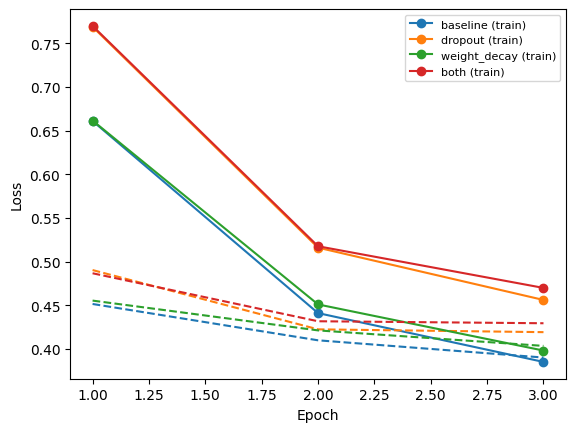

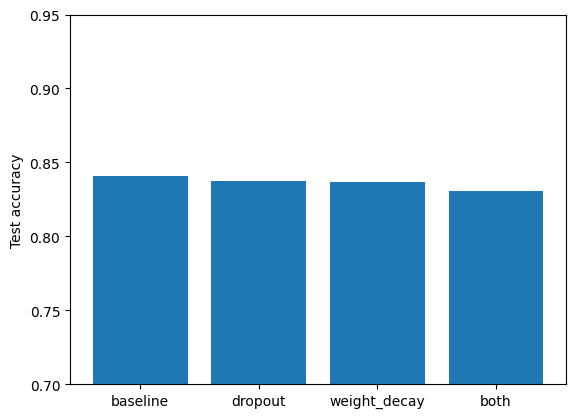

In [12]:
for name, h in histories.items():
    line, = plt.plot(h["epoch"], h["train_loss"], marker="o", label=name + " (train)")
    plt.plot(h["epoch"], h["val_loss"], linestyle="--", color=line.get_color())
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(fontsize=8)
plt.savefig('outputs/loss.png')
plt.show()

plt.bar(results["condition"], results["test_accuracy"])
plt.ylabel("Test accuracy")
plt.ylim(0.7, 0.95)
plt.savefig('outputs/regularization_accuracy.png')
plt.show()